Define repositório

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json
import csv

class File:

  def __init__(self, path):
    self.path = path

  def read(self):
    with open(self.path, "r") as file:
      if self.path.endswith(".json"):
        return json.load(file)
      elif self.path.endswith(".csv"):
        result = []
        reader = csv.DictReader(file)
        for row in reader:
          result.append(row)
        return result
        
    return None

  def write(self, data):
    with open(self.path, "w") as file:
      if self.path.endswith(".json"):
        json.dump(data, file, indent = 2, sort_keys=True)
        print(f"> write {self.path}")

import os

class Folder:

  def __init__(self, base):
    self.base = base

  def all_files(self):
    result = []
    self.__all_files_recursive(result, self.base)
    return result

  def __all_files_recursive(self, result, folder):
    for file in os.listdir(folder):
      if os.path.isdir(f"{folder}/{file}"):
        self.__all_files_recursive(result, f"{folder}/{file}")
      else: 
        filepath = os.path.join(folder, file)
        result.append(filepath)
        

  def all_files_by_ext(self, ext=".json"):
    result = []
    for file in self.all_files():
      if file.endswith(ext):
        result.append(file)
    return result

  def all_files_with_pattern(self, pattern):
    result = []
    for file in self.all_files():
      if pattern in file:
        result.append(file)
    return result
  
  def file(self, path):
    return File(path)

  def create(self):
    if not os.path.exists(self.base):
      os.makedirs(self.base)

  

In [3]:
base = "drive/My Drive/Colab Notebooks"
repository = "findbugs"

inicio = 13000
fim = 15100

Leitura do arquivo de commits

In [4]:
commits_file = File(f"{base}/metadata/{repository}/commits.json").read()
#commits_file[:5]

Define função de leitura de ZIP

In [ ]:
#ler arquivo zip
import zipfile
import json

#multipattern_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip", "r")
def read_file_from_zip(zipfile, file):
  data = zipfile.read(file)
  return json.loads(data.decode("utf-8"))

Contagem dos tipos de mapeamentos por commit

In [ ]:
mapeamentos_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/mappings.zip")
result = mapeamentos_zip.namelist()[:10]
#print(result)

resultado = []
for commit in commits_file[inicio:fim]:
  tipos = {
      "insert": 0,
      "delete": 0,
      "update": 0,
      "move": 0
  }
  file = read_file_from_zip(mapeamentos_zip, f"{commit}.json")
  for mapping in file["mappings"]:
    type = mapping["type"]
    tipos[type] = tipos[type] + 1
  resultado.append(tipos)

mapeamentos_zip.close()


In [ ]:
resultado[:5]

[{'delete': 0, 'insert': 0, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 6, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 3, 'move': 0, 'update': 0},
 {'delete': 14, 'insert': 21, 'move': 0, 'update': 7},
 {'delete': 0, 'insert': 0, 'move': 0, 'update': 0}]

Gráfico de Contagem de Tipos de Mapemantos por Commit

In [ ]:
result = {
    "insert": 0,
    "delete": 0,
    "update": 0,
    "move": 0
}

for item in resultado:
  result["insert"] = result["insert"] + item["insert"]
  result["delete"] = result["delete"] + item["delete"]
  result["update"] = result["update"] + item["update"]
  result["move"] = result["move"] + item["move"]

result["total"] = result["move"] + result["update"] + result["delete"] + result["insert"]
  
print(result)

{'insert': 12250, 'delete': 4818, 'update': 2535, 'move': 2505, 'total': 22108}


In [ ]:
insert = []
delete = []
update = []
move = []

for item in resultado:
  insert.append(item["insert"])
  delete.append(item["delete"])
  update.append(item["update"])
  move.append(item["move"])

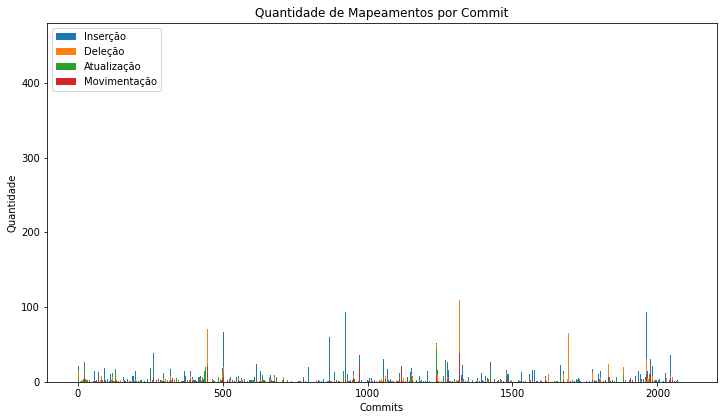

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig = plt.gcf()
fig.set_size_inches(12, 6.6)

tamanho = fim - inicio
indices = np.arange(tamanho)

pInsert = plt.bar(indices, insert)
pDelete = plt.bar(indices, delete)
pUpdate = plt.bar(indices, update)
pMove = plt.bar(indices, move)

plt.title("Quantidade de Mapeamentos por Commit")
plt.ylabel("Quantidade")
plt.xlabel("Commits")
plt.ylim(top=480)

plt.legend((pInsert[0],pDelete[0], pUpdate[0], pMove[0]), ('Inserção','Deleção', 'Atualização', 'Movimentação'))

plt.show()

Define gráfico Multipattern

In [ ]:
from google.colab import files

def plot(x, data1, data2):
  fig, ax1 = plt.subplots()
  ax1.set_xlabel('Commit')
  
  color = 'tab:red'
  ax1.set_ylabel('Quantidade', color=color)
  ax1.plot(x, data1, color=color)
  ax1.tick_params(axis='y', labelcolor=color)

  color = 'tab:blue'
  ax2 = ax1.twinx()
  ax2.set_ylabel('Média da variação da manut.\n por commit', color=color)  # we already handled the x-label with ax1
  ax2.plot(x, data2, color=color)
  ax2.tick_params(axis='y', labelcolor=color)

  #plt.title("Quantidade de Modificações e Variação da\n Manutenabilidade por commit")
  fig.set_size_inches(12, 6.6)
  #plt.show()
  plt.savefig("multipattern.pdf",  bbox_inches='tight')
  files.download("multipattern.pdf")

Gerar gráfico

In [ ]:
data_file = File(f"{base}/metadata/{repository}/analise-multipattern.json").read()
posicoes = np.arange(start=inicio, stop=fim, step=1)
quantidades = []
medias = []

for commit in commits_file[inicio:fim]:
  if commit in data_file:
    values = data_file[commit].values()
    quantidade = len(values)
    media = 0
    for value in values:
      media = media + value
    media = media/quantidade
  else:
    media = 0
    quantidade = 0
  quantidades.append(quantidade)
  medias.append(media)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

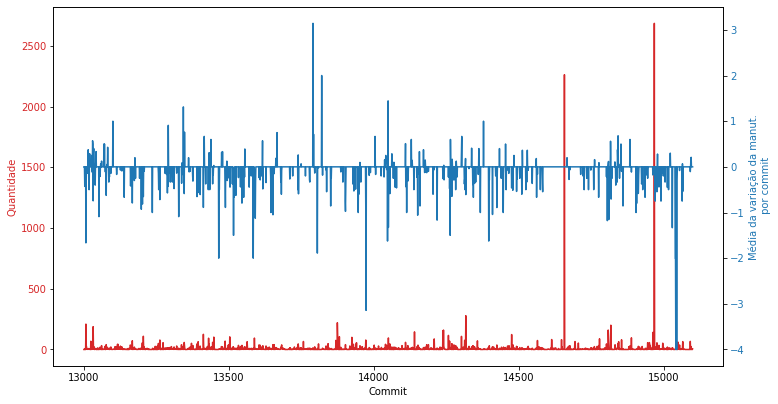

In [ ]:
plot(posicoes, quantidades, medias)

Define função do gráfico de Distribuição de Manutenabilidade por Padrão de Modificação

In [ ]:
def plot_box(keys, values):
    fig, ax = plt.subplots()
    bp = ax.boxplot(
        values, 
        sym='k+'
    )

    ax.set_xlabel('Padrões de Modificação')
    ax.set_ylabel('Dist. do Índice de Manutenabilidade')
    plt.setp(bp['whiskers'], color='k', linestyle='-')
    plt.setp(bp['fliers'], markersize=3.0)
    plt.title("Distribuição de Manutenabilidade por Padrão de Modificação")

    plt.xticks(np.arange(len(keys))+1, keys, rotation=55)
    fig.set_size_inches(15, 8)
    #plt.show()
    plt.savefig("boxplot-arquivos.pdf",  bbox_inches='tight')
    files.download("boxplot-arquivos.pdf")

Processamento da Distribuição de Manutenabilidade

In [ ]:
file = File(f"{base}/metadata/{repository}/clusters-manutenabilidade.json")
clusters = file.read()


# Lista dos maiores agrupamentos de cada repositorio

# In[19]:


arquivo = File(f"{base}/metadata/{repository}/distribuicao-tamanhos-clusters.json").read()
conjunto = []
sizes = []
for tamanho, data in arquivo.items():
    tamanho = int(tamanho)
    sizes.insert(0, tamanho)
    if tamanho > 1:
        for item in data["items"]:
            conjunto.insert(0, item)

In [ ]:
len(conjunto)

99

In [ ]:
import statistics

clusters_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/clusters.zip")

result = {}
for index in conjunto:
  cluster = read_file_from_zip(clusters_zip, f"clusters/{index}.json")
  adicionar = False
  for item in cluster["base"]["items"]:
    if item["type"] == "move" or item["type"] == "update":
      adicionar = True
  
  if adicionar:
    result[index] = clusters[index]["indexes"]

elementos = {k: v for k, v in sorted(result.items(), key=lambda item: statistics.mean(item[1]))}

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

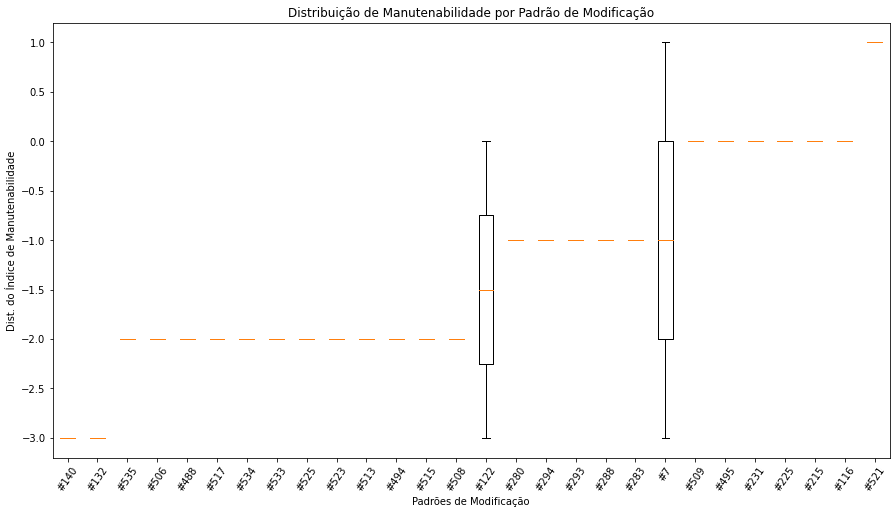

In [ ]:
all_keys = list(elementos.keys())
all_values = list(elementos.values())
plot_box(all_keys, all_values)

Lista de padrões de modificações com número de ocorrências >= 2

In [ ]:
result = {}
for index in conjunto:
  cluster = read_file_from_zip(clusters_zip, f"clusters/{index}.json")
  adicionar = False
  for item in cluster["base"]["items"]:
    if item["type"] == "move" or item["type"] == "update":
      #print(item["type"])
      adicionar = True
  if adicionar:
    result[index] = clusters[index]["indexes"]

ordered = {k: v for k, v in sorted(result.items(), key=lambda item: statistics.mean(item[1]))}

print(list(ordered.keys()))

['#140', '#132', '#535', '#506', '#488', '#517', '#534', '#533', '#525', '#523', '#513', '#494', '#515', '#508', '#122', '#280', '#294', '#293', '#288', '#283', '#7', '#509', '#495', '#231', '#225', '#215', '#116', '#521']


Distribuição de tamanhos dos padrões de modificações

In [ ]:
arquivo = File(f"{base}/metadata/{repository}/distribuicao-tamanhos-clusters.json").read()
elementos = {}
for tamanho, data in arquivo.items():
  if int(tamanho) > 1:
    elementos[int(tamanho)] = data['quantidade']
print(elementos)

{2: 49, 3: 28, 4: 9, 6: 7, 7: 2, 8: 2, 42: 1, 54: 1}


In [ ]:
import matplotlib.pyplot as plt

def plot_distribuicao_tamanhos(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Distribuição da Quantidade de Ocorrências de Padrões de Modificação")
  plt.ylabel("Quantidade")
  plt.xlabel("Tamanho")
  plt.xticks(rotation=45)
  plt.yscale("log")
  plt.yticks(ticks=[1,10,20,50,100,200], labels=[1,10,20,50,100,200])
  plt.show()

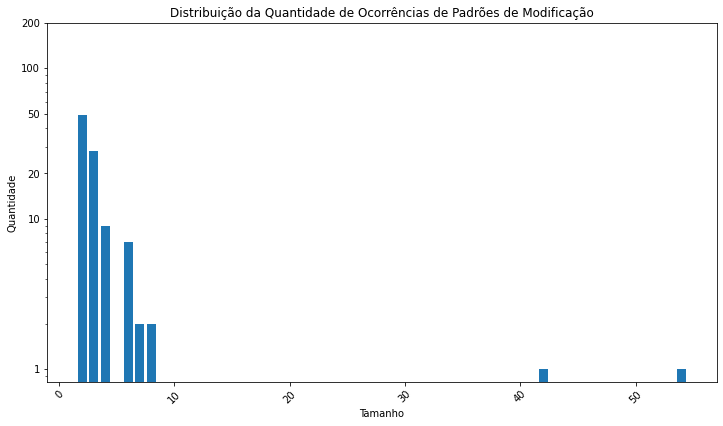

In [ ]:
plot_distribuicao_tamanhos(elementos)

In [ ]:
soma = 0
for item in elementos.values():
  soma = soma + item
print(soma)

99
